In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
import joblib

# Chargement de la table nettoyee
df = pd.read_csv('../data/freMTPL2_clean.csv')
print('Table chargee :', df.shape)
df.head()

Table chargee : (678013, 13)


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,ClaimAmount
0,1.0,1,0.10,'D',5,0,55,50,'B12','Regular',1217,'R82',0.0
1,3.0,1,0.77,'D',5,0,55,50,'B12','Regular',1217,'R82',0.0
2,5.0,1,0.75,'B',6,2,52,50,'B12','Diesel',54,'R22',0.0
3,10.0,1,0.09,'B',7,0,46,50,'B12','Diesel',76,'R72',0.0
4,11.0,1,0.84,'B',7,0,46,50,'B12','Diesel',76,'R72',0.0


# GLM Poisson — Modele de frequence des sinistres

## Objectif
Modeliser le nombre de sinistres par police en fonction du profil client.
On utilise un GLM avec une loi de Poisson car :
- La variable reponse (ClaimNb) est un comptage d'evenements rares
- 95% des polices ont 0 sinistre
- La distribution observee suit bien une loi de Poisson

## Formule du modele
log(E[ClaimNb]) = log(Exposure) + b0 + b1*BonusMalus + b2*DrivAge + ...

Le terme log(Exposure) est un offset — il corrige le fait que certains
contrats couvrent moins d'un an. Sans cet offset le modele serait biaise.

## Variables explicatives retenues
- BonusMalus : principale variable de risque
- DrivAge : l'age du conducteur (via tranches)
- VehAge : l'age du vehicule
- VehPower : la puissance du vehicule
- Region : la zone geographique
- VehGas : le type de carburant
- Density : la densite de population

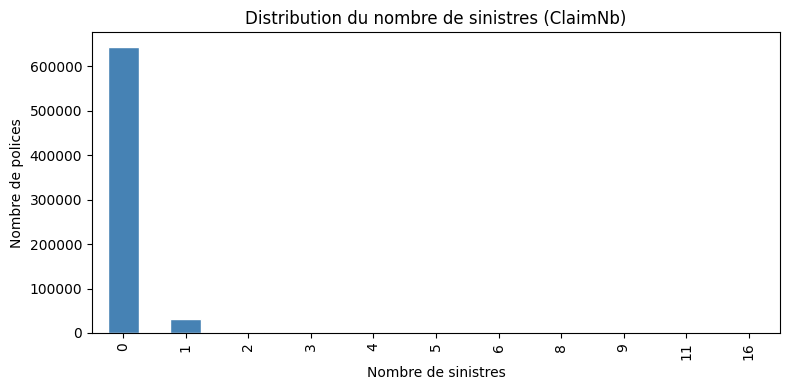

Moyenne ClaimNb  : 0.0532
Variance ClaimNb : 0.0577


In [18]:
# Histogramme ClaimNb — justification du choix de la loi de Poisson
fig, ax = plt.subplots(figsize=(8, 4))
df['ClaimNb'].value_counts().sort_index().plot(kind='bar', color='steelblue', edgecolor='white', ax=ax)
ax.set_title('Distribution du nombre de sinistres (ClaimNb)')
ax.set_xlabel('Nombre de sinistres')
ax.set_ylabel('Nombre de polices')
plt.tight_layout()
plt.show()

print('Moyenne ClaimNb  :', round(df['ClaimNb'].mean(), 4))
print('Variance ClaimNb :', round(df['ClaimNb'].var(), 4))

## Justification du choix de la loi de Poisson

Ce graphique confirme que la distribution de ClaimNb suit bien une loi de Poisson :
- 95% des polices ont 0 sinistre — evenement rare
- Decroissance tres rapide au-dela de 1 sinistre
- Moyenne ≈ Variance (propriete cle de la loi de Poisson)
- La loi de Poisson est le standard actuariel pour modeliser des comptages de sinistres

In [19]:
# Train/test split 85% / 15%
train, test = train_test_split(df, test_size=0.15, random_state=42)

print('Taille train :', len(train))
print('Taille test  :', len(test))
print()
print('Moyenne ClaimNb train :', round(train['ClaimNb'].mean(), 4))
print('Moyenne ClaimNb test  :', round(test['ClaimNb'].mean(), 4))
print()
print('=> Distributions similaires : le split est representatif')

Taille train : 576311
Taille test  : 101702

Moyenne ClaimNb train : 0.0533
Moyenne ClaimNb test  : 0.053

=> Distributions similaires : le split est representatif


In [23]:
# Preparation des donnees
train = train.copy()
test  = test.copy()

# Offset = log(Exposure)
train['log_exposure'] = np.log(train['Exposure'])
test['log_exposure']  = np.log(test['Exposure'])

# Transformation log(BonusMalus) pour capturer l'effet non-lineaire
train['log_bonus_malus'] = np.log(train['BonusMalus'])
test['log_bonus_malus']  = np.log(test['BonusMalus'])
train['tranche_age'] = pd.cut(train['DrivAge'],
    bins=[18, 25, 35, 45, 55, 65, 100],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65', '65+'])

test['tranche_age'] = pd.cut(test['DrivAge'],
    bins=[18, 25, 35, 45, 55, 65, 100],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65', '65+'])

# Nettoyage guillemets dans les colonnes categorielles
for col in ['Area', 'VehBrand', 'VehGas', 'Region']:
    train[col] = train[col].str.replace("'", "")
    test[col]  = test[col].str.replace("'", "")

# Regroupement des regions non significatives (identifiees apres test v1)
regions_non_sig = ['R21', 'R22', 'R23', 'R24', 'R25', 'R26', 'R42', 'R43']
train['Region_v3'] = train['Region'].apply(lambda x: 'Autre' if x in regions_non_sig else x)
test['Region_v3']  = test['Region'].apply(lambda x: 'Autre' if x in regions_non_sig else x)

print('Preparation des donnees terminee !')

Preparation des donnees terminee !


# Amelioration iterative du modele GLM Poisson

On teste 4 versions du modele pour identifier la specification optimale :
- **v1** : modele de base avec variables brutes
- **v2** : log(BonusMalus) + tranches d'age au lieu de DrivAge brut
- **v3** : v2 + regroupement des regions non significatives
- **v4** : v3 + interaction log(BonusMalus) x tranche_age

Criteres de comparaison : Pseudo R², AIC, BIC

In [24]:
# Modele v1 — basique
model_v1 = smf.glm(
    formula='ClaimNb ~ BonusMalus + VehAge + VehPower + DrivAge + Region + VehGas + Density',
    data=train,
    family=sm.families.Poisson(),
    offset=train['log_exposure']
).fit()

print(model_v1.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               576311
Model:                            GLM   Df Residuals:                   576283
Model Family:                 Poisson   Df Model:                           27
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.2200e+05
Date:                Mon, 01 Jun 2026   Deviance:                   1.8502e+05
Time:                        19:00:26   Pearson chi2:                 1.54e+06
No. Iterations:                     7   Pseudo R-squ. (CS):            0.01017
Covariance Type:            nonrobust                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -3.8159      0

In [25]:
# Modele v2 — log(BonusMalus) + tranches d'age
model_v2 = smf.glm(
    formula='ClaimNb ~ log_bonus_malus + VehAge + VehPower + tranche_age + Region + VehGas + Density',
    data=train,
    family=sm.families.Poisson(),
    offset=train['log_exposure']
).fit()

print('Pseudo R2 v1 :', round(model_v1.pseudo_rsquared(), 4))
print('Pseudo R2 v2 :', round(model_v2.pseudo_rsquared(), 4))
print('AIC v1 :', round(model_v1.aic, 2))
print('AIC v2 :', round(model_v2.aic, 2))

Pseudo R2 v1 : 0.0102
Pseudo R2 v2 : 0.0107
AIC v1 : 244061.5
AIC v2 : 243338.82


In [26]:
# Modele v3 — regroupement regions non significatives
model_v3 = smf.glm(
    formula='ClaimNb ~ log_bonus_malus + VehAge + VehPower + tranche_age + Region_v3 + VehGas + Density',
    data=train,
    family=sm.families.Poisson(),
    offset=train['log_exposure']
).fit()

print('Pseudo R2 v2 :', round(model_v2.pseudo_rsquared(), 4))
print('Pseudo R2 v3 :', round(model_v3.pseudo_rsquared(), 4))
print('AIC v2 :', round(model_v2.aic, 2))
print('AIC v3 :', round(model_v3.aic, 2))

Pseudo R2 v2 : 0.0107
Pseudo R2 v3 : 0.0107
AIC v2 : 243338.82
AIC v3 : 243338.82


In [27]:
# Modele v4 — interaction log_bonus_malus x tranche_age
model_v4 = smf.glm(
    formula='ClaimNb ~ log_bonus_malus * tranche_age + VehAge + VehPower + Region_v3 + VehGas + Density',
    data=train,
    family=sm.families.Poisson(),
    offset=train['log_exposure']
).fit()

print('Pseudo R2 v3 :', round(model_v3.pseudo_rsquared(), 4))
print('Pseudo R2 v4 :', round(model_v4.pseudo_rsquared(), 4))
print('AIC v3 :', round(model_v3.aic, 2))
print('AIC v4 :', round(model_v4.aic, 2))

Pseudo R2 v3 : 0.0107
Pseudo R2 v4 : 0.011
AIC v3 : 243338.82
AIC v4 : 243185.87


In [28]:
# Tableau comparatif AIC / BIC / R2
print('Comparaison AIC / BIC / R2 :')
print(f'v1 — AIC : {round(model_v1.aic, 2)}, BIC : {round(model_v1.bic, 2)}, R2 : {round(model_v1.pseudo_rsquared(), 4)}')
print(f'v2 — AIC : {round(model_v2.aic, 2)}, BIC : {round(model_v2.bic, 2)}, R2 : {round(model_v2.pseudo_rsquared(), 4)}')
print(f'v3 — AIC : {round(model_v3.aic, 2)}, BIC : {round(model_v3.bic, 2)}, R2 : {round(model_v3.pseudo_rsquared(), 4)}')
print(f'v4 — AIC : {round(model_v4.aic, 2)}, BIC : {round(model_v4.bic, 2)}, R2 : {round(model_v4.pseudo_rsquared(), 4)}')
print()
print('=> Modele retenu : v4 (meilleur AIC et R2)')

Comparaison AIC / BIC / R2 :
v1 — AIC : 244061.5, BIC : -7459026.36, R2 : 0.0102
v2 — AIC : 243338.82, BIC : -7450780.22, R2 : 0.0107
v3 — AIC : 243338.82, BIC : -7450780.22, R2 : 0.0107
v4 — AIC : 243185.87, BIC : -7450876.86, R2 : 0.011

=> Modele retenu : v4 (meilleur AIC et R2)


/Users/marionrenaud/Desktop/Projet Clopeau/tarification-iard/venv/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1923: FutureWarning: The bic value is computed using the deviance formula. After 0.13 this will change to the log-likelihood based formula. This change has no impact on the relative rank of models compared using BIC. You can directly access the log-likelihood version using the `bic_llf` attribute. You can suppress this message by calling statsmodels.genmod.generalized_linear_model.SET_USE_BIC_LLF with True to get the LLF-based version now or False to retainthe deviance version.
  warnings.warn(


# Validation du modele v4 sur le jeu de test

On evalue le modele retenu (v4) sur les 101 702 polices du jeu de test —
donnees jamais vues pendant l'entrainement, simulant de vrais nouveaux clients.

In [29]:
# Calibration sur le jeu de test
test['freq_predite'] = model_v4.predict(test, offset=test['log_exposure'])

print('Moyenne observee (test) :', round(test['ClaimNb'].mean(), 4))
print('Moyenne predite  (test) :', round(test['freq_predite'].mean(), 4))
print()
ecart = abs(test['ClaimNb'].mean() - test['freq_predite'].mean()) / test['ClaimNb'].mean() * 100
print(f'Ecart relatif : {round(ecart, 2)}% => modele bien calibre')

Moyenne observee (test) : 0.053
Moyenne predite  (test) : 0.0532

Ecart relatif : 0.42% => modele bien calibre


   decile  freq_predite  freq_observee
0     0.0      0.003473       0.023824
1     1.0      0.008968       0.026386
2     2.0      0.017038       0.031702
3     3.0      0.028281       0.042532
4     4.0      0.040985       0.046564
5     5.0      0.053219       0.049818
6     6.0      0.064982       0.056020
7     7.0      0.077738       0.066358
8     8.0      0.093981       0.069213
9     9.0      0.143325       0.116558

Lift decile 10 : 2.2


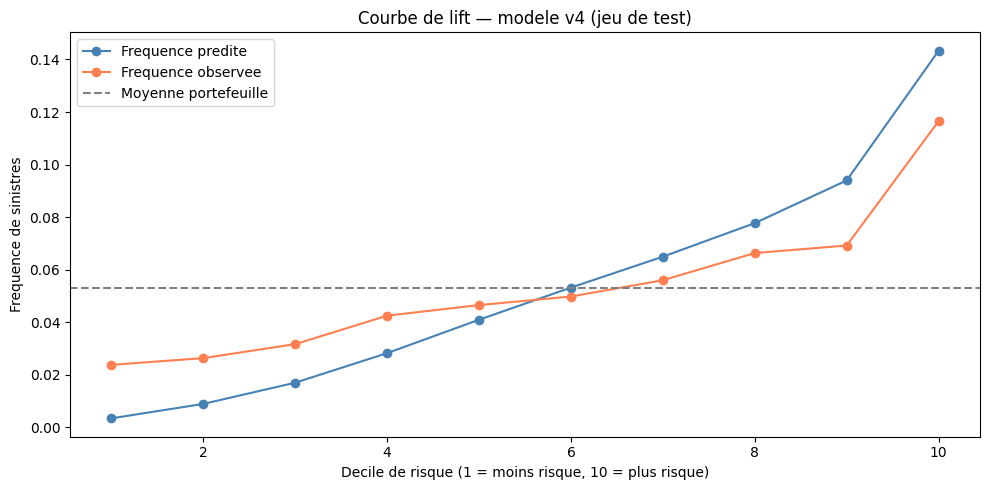

In [30]:
# Courbe de lift sur le jeu de test
test['decile'] = pd.qcut(test['freq_predite'], 10, labels=False)

lift = test.groupby('decile').agg(
    freq_predite=('freq_predite', 'mean'),
    freq_observee=('ClaimNb', 'mean')
).reset_index()

print(lift)
lift_d10 = lift[lift['decile'] == 9]['freq_observee'].values[0] / test['ClaimNb'].mean()
print(f'\nLift decile 10 : {round(lift_d10, 3)}')

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(lift['decile']+1, lift['freq_predite'], marker='o', label='Frequence predite', color='steelblue')
ax.plot(lift['decile']+1, lift['freq_observee'], marker='o', label='Frequence observee', color='coral')
ax.axhline(y=test['ClaimNb'].mean(), color='gray', linestyle='--', label='Moyenne portefeuille')
ax.set_title('Courbe de lift — modele v4 (jeu de test)')
ax.set_xlabel('Decile de risque (1 = moins risque, 10 = plus risque)')
ax.set_ylabel('Frequence de sinistres')
ax.legend()
plt.tight_layout()
plt.show()

Coefficient de Gini : 0.262


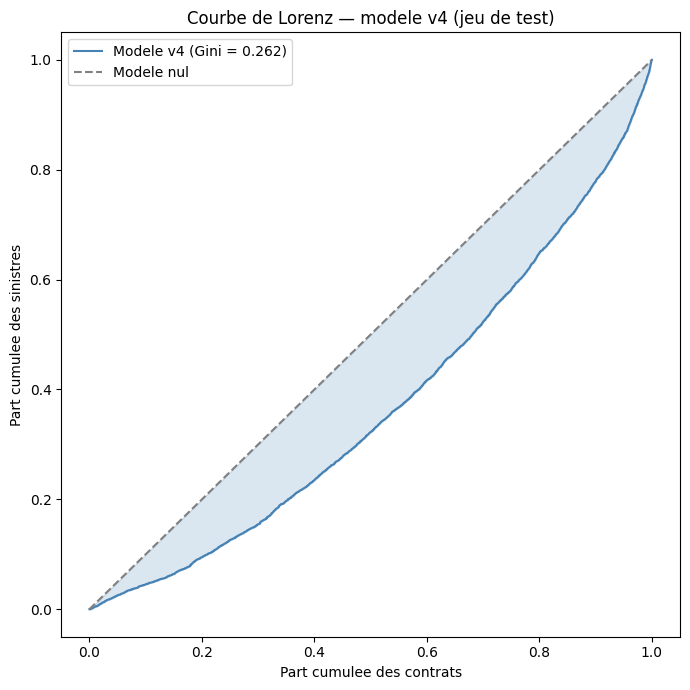

In [31]:
# Courbe de Lorenz et coefficient de Gini
test_sorted = test.sort_values('freq_predite')
cumul_population = np.arange(1, len(test_sorted)+1) / len(test_sorted)
cumul_sinistres  = test_sorted['ClaimNb'].cumsum() / test_sorted['ClaimNb'].sum()
gini = 1 - 2 * np.trapezoid(cumul_sinistres, cumul_population)
print('Coefficient de Gini :', round(gini, 4))

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(cumul_population, cumul_sinistres, color='steelblue', label=f'Modele v4 (Gini = {round(gini, 4)})')
ax.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Modele nul')
ax.fill_between(cumul_population, cumul_sinistres, cumul_population, alpha=0.2, color='steelblue')
ax.set_title('Courbe de Lorenz — modele v4 (jeu de test)')
ax.set_xlabel('Part cumulee des contrats')
ax.set_ylabel('Part cumulee des sinistres')
ax.legend()
plt.tight_layout()
plt.show()

Residus de Pearson :
Moyenne : 0.0626
Std     : 1.6706


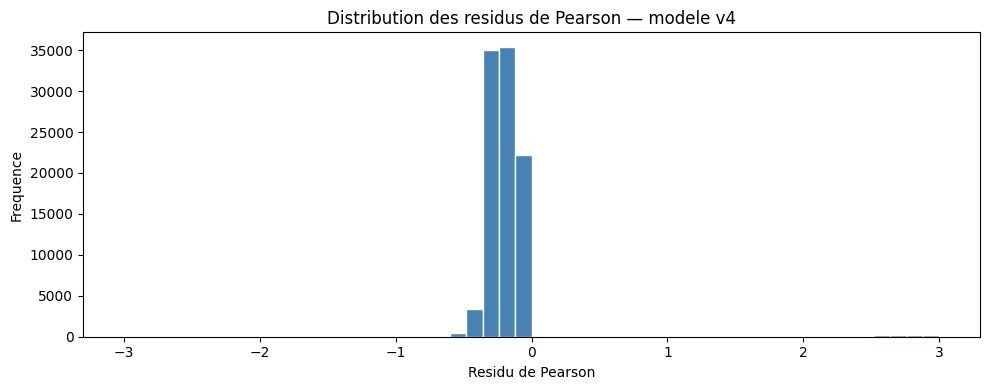

In [32]:
# Residus de Pearson
test['residus_pearson'] = (test['ClaimNb'] - test['freq_predite']) / np.sqrt(test['freq_predite'])

print('Residus de Pearson :')
print('Moyenne :', round(test['residus_pearson'].mean(), 4))
print('Std     :', round(test['residus_pearson'].std(), 4))

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(test['residus_pearson'], bins=50, color='steelblue', edgecolor='white', range=(-3, 3))
ax.set_title('Distribution des residus de Pearson — modele v4')
ax.set_xlabel('Residu de Pearson')
ax.set_ylabel('Frequence')
plt.tight_layout()
plt.show()

# Limites et perspectives : surdispersion

L'ecart-type des residus de Pearson (> 1) suggere une surdispersion.
On la quantifie formellement et on teste un modele Binomial Negatif comme perspective d'amelioration.

In [34]:
# Test de surdispersion formel
ratio = model_v4.pearson_chi2 / model_v4.df_resid
print('Pearson chi2 :', round(model_v4.pearson_chi2, 2))
print('Df residuels :', model_v4.df_resid)
print('Ratio surdispersion :', round(ratio, 4))
print()
if ratio > 1.5:
    print('=> Surdispersion detectee (ratio >> 1)')
    print('   La variance reelle est plus grande que ce que suppose la loi de Poisson')
    print('   Perspective : modele Binomial Negatif')

Pearson chi2 : 1527719.82
Df residuels : 575655
Ratio surdispersion : 2.6539

=> Surdispersion detectee (ratio >> 1)
   La variance reelle est plus grande que ce que suppose la loi de Poisson
   Perspective : modele Binomial Negatif


In [35]:
# Perspective : Binomial Negatif
model_bn = smf.glm(
    formula='ClaimNb ~ log_bonus_malus * tranche_age + VehAge + VehPower + Region_v3 + VehGas + Density',
    data=train,
    family=sm.families.NegativeBinomial(),
    offset=train['log_exposure']
).fit()

ratio_bn = model_bn.pearson_chi2 / model_bn.df_resid

print('=== COMPARAISON FINALE ===')
print(f'Poisson v4       — AIC : {round(model_v4.aic, 2)}, Ratio surdispersion : {round(ratio, 4)}')
print(f'Binomial Negatif — AIC : {round(model_bn.aic, 2)}, Ratio surdispersion : {round(ratio_bn, 4)}')
print()
print('=> Le Binomial Negatif ameliore l AIC et reduit la surdispersion')
print('   Modele retenu pour la prime pure : Poisson v4 (conforme au sujet)')
print('   Binomial Negatif : perspective d amelioration future')

/Users/marionrenaud/Desktop/Projet Clopeau/tarification-iard/venv/lib/python3.13/site-packages/statsmodels/genmod/families/family.py:1367: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  warnings.warn("Negative binomial dispersion parameter alpha not "


=== COMPARAISON FINALE ===
Poisson v4       — AIC : 243185.87, Ratio surdispersion : 2.6539
Binomial Negatif — AIC : 242520.35, Ratio surdispersion : 2.5632

=> Le Binomial Negatif ameliore l AIC et reduit la surdispersion
   Modele retenu pour la prime pure : Poisson v4 (conforme au sujet)
   Binomial Negatif : perspective d amelioration future


In [16]:
# Sauvegarde du modele final v4
joblib.dump(model_v4, '../models/glm_poisson.pkl')
print('Modele GLM Poisson v4 sauvegarde dans models/glm_poisson.pkl')
print('Pret a etre utilise par Mario (prime pure) et Streamlit (application)')

Modele GLM Poisson v4 sauvegarde dans models/glm_poisson.pkl
Pret a etre utilise par Mario (prime pure) et Streamlit (application)
